# Reto Planta Física
# Parte 1: Investigación

| | |
|---|---|
| **Grupo** | 201 |
| **Equipo** | 11 |

| Integrante | Matrícula |
|---|---|
| A01668975 | Jesús Emilio Arroyo Camarena |
| A01660285 | Diana Paulina Cano García |
| A00841256 | Fátima Sofía Sacoto Idrovo |

### Responsabilidades y rotaciones

| Rol | Integrante | Qué hizo | Rotación |
|---|---|---|---|
| Programación | Jesús Emilio Arroyo Camarena | Se encargó del código | NO |
| Revisión | Fátima Sofía Sacoto Idrovo  | Revisión del código y redacción | NO |
| Verificación | Diana Paulina Cano García| Verificación de resultados y presentación | NO |

### Cambios

Conservamos todas las secciones de la base común (1 a 11 y Procedencia y entorno). Las celdas que agregamos para Investigación llevan el encabezado Investigación y están junto al contenido que complementan, organizadas en cuatro apartados:

1. Formulación y supuestos.
2. Cálculo manual.
3. Comparación con `evaluate`.
4. Interpretación y correcciones.

Esta libreta integra en un solo archivo la base común (`reto_planta_fisica_solucion_minima.ipynb`) y la evidencia de Investigación.

# Planta Física


## 1. Definir el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como capacidad didáctica, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [ ]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])
LIMITS = np.array([8, 8, 6, 8])
CAPACITY = 1410.0

## Apartado 1: formulación y supuestos

### 1.1 La decisión física y los genes

Para cada uno de los cuatro edificios decidimos qué porcentaje de su demanda mensual cubrimos con agua tratada (reúso), mediante cuatro niveles enteros $k=(k_1,k_2,k_3,k_4)$. El resto de la demanda lo cubre agua potable. Permanecen fijos: las demandas $D_i$, la capacidad $C$ y los dominios de cada gen.   

Conservamos siempre el mismo orden en las tablas, el cromosoma y el código:

| Posición | Gen | Edificio | Dominio entero de $k_i$ | Fracción $x_i=k_i/10$ | Reúso máximo | Valores posibles |
|---|---|---|---|---|---|---|
| 1 | $k_1$ | Aulas 1 | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |
| 2 | $k_2$ | Biblioteca | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |
| 3 | $k_3$ | Cedetec | 0 a 6 | 0.0 a 0.6 | 60 % | 7 |
| 4 | $k_4$ | Aulas 2 | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |

Distinguimos tres magnitudes:

- Nivel entero $k_i$ (el gen): número entero sin unidades. Cada nivel equivale a diez puntos porcentuales.
- Fracción $x_i=k_i/10$: número sin unidades entre 0 y 1; el porcentaje de reúso es $100x_i$.
- Volumen $T_i=D_i\,k_i/10$: cantidad de agua tratada en m³.

Ejemplo: $k_3=6$ en Cedetec representa $x_3=0.60$, es decir 60 % de su demanda, y $T_3=284.21\times0.6=170.526$ m³. Nunca usamos $k_i$ directamente como fracción. En Cedetec el nivel 8 no es válido porque su máximo didáctico es 60 %.

### 1.2 Datos fijos

Demandas agregadas de marzo de 2025, en m³ (consumos observados):

| Edificio | Mes | Demanda $D_i$ (m³) |
|---|---|---|
| Aulas 1 | marzo de 2025 | 847.00 |
| Biblioteca | marzo de 2025 | 462.00 |
| Cedetec | marzo de 2025 | 284.21 |
| Aulas 2 | marzo de 2025 | 683.00 |
| Total $Q$ | marzo de 2025 | 2276.21 |

Las demandas provienen del archivo `consumo_agua_2023_2026.csv` del kit del repositorio técnico MA2015-Planta-Fisica (cuyo registro de origen es `consumo-agua.xlsx`, con fecha de corte 2026-08-21), filtrado a marzo de 2025 e incorporado en la base de esta libreta; la metadata de la libreta conserva los cuatro registros y los hashes de las fuentes completas. Cada $D_i$ es la suma del agua tratada y la potable registradas en el mes (por ejemplo, Aulas 1: 647.0 + 200.0 = 847.0 m³). Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

### 1.3 Objetivo, fórmulas y restricción

Para un cromosoma $k$:

$$T_i=\frac{D_i\,k_i}{10},\qquad P_i=D_i-T_i,\qquad T=\sum_{i=1}^{4}T_i,\qquad P=Q-T,\qquad E=\max(0,\,T-C)$$

$$F(k)=\begin{cases}\dfrac{P}{Q} & \text{si } T\le C\ \ (\text{factible})\\[2mm] 1+\dfrac{E}{C} & \text{si } T>C\ \ (\text{infactible})\end{cases}$$

$T_i$ y $P_i$ son los volúmenes tratado y potable del edificio $i$; $T$ y $P$ son los totales; $E$ es el exceso de capacidad. Todos están en m³; $k_i$, $x_i$ y $F$ no tienen unidades.

Minimizamos el agua potable $P$ sujeto a los dominios y a $T\le C$. Cada m³ de agua tratada que usamos sustituye un m³ de agua potable, así que reducir $P$ equivale a aprovechar más el reúso, pero sólo hasta donde la planta alcanza.

$F$ es una aptitud donde menor es mejor. Para un plan factible, $F=P/Q$ es la fracción de la demanda que sigue cubierta con agua potable, y por eso $F\le1$. Un plan que rebasa la capacidad recibe $F=1+E/C>1$, de modo que cualquier plan factible es mejor que cualquier plan infactible. En código, la factibilidad se comprueba con tolerancia numérica: un candidato cumple si $E\le10^{-8}$ m³. Un cromosoma fuera de dominio o con valores no enteros se rechaza (la función lanza un error); un cromosoma válido que rebasa la capacidad se evalúa por la rama infactible.

### 1.4 Datos observados frente a supuestos didácticos

| Elemento | Valor | Naturaleza |
|---|---|---|
| Demandas $D_i$ de marzo de 2025 | 847.00, 462.00, 284.21, 683.00 m³ | Consumos observados |
| Capacidad $C$ | 1410 m³ | Supuesto didáctico, tomado de la calibración docente existente; no es una capacidad confirmada por el socio |
| Reúso máximo por edificio | 80 %, 80 %, 60 %, 80 % | Supuestos didácticos |
| Tolerancia de factibilidad | $10^{-8}$ m³ | Decisión técnica de cálculo numérico |

### 1.5 Alcance

El modelo describe un ejercicio mensual (marzo de 2025) con cuatro edificios. No representa un año completo ni otros meses, y sus resultados no constituyen una recomendación hidráulica o sanitaria validada.

In [ ]:
# Verificación de los datos y dominios que acabamos de documentar
assert BUILDINGS == ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
Q = float(np.sum(DEMAND))
print(f"Demanda total Q = {Q:.2f} m³")
print(f"Capacidad didáctica C = {CAPACITY:.0f} m³")
print(f"Combinaciones posibles = {int(np.prod(LIMITS + 1))}")
print()
print(f"{'gen':<5}{'edificio':<12}{'D_i (m³)':>10}{'dominio':>10}{'x_i máx':>10}{'reúso máx':>11}")
for i, (name, d, lim) in enumerate(zip(BUILDINGS, DEMAND, LIMITS), start=1):
    print(f"k{i:<4}{name:<12}{d:>10.2f}{'0 a ' + str(lim):>10}{lim / 10:>10.1f}{lim * 10:>10d} %")
assert np.isclose(Q, 2276.21)

Demanda total Q = 2276.21 m³
Capacidad didáctica C = 1410 m³
Combinaciones posibles = 5103

gen  edificio      D_i (m³)   dominio   x_i máx  reúso máx
k1   AULAS 1         847.00     0 a 8       0.8        80 %
k2   BIBLIOTECA      462.00     0 a 8       0.8        80 %
k3   CEDETEC         284.21     0 a 6       0.6        60 %
k4   AULAS 2         683.00     0 a 8       0.8        80 %


## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. Menor aptitud es mejor. Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [ ]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

## Apartado 2: cálculo manual

Elegimos el cromosoma $k=(6,6,6,6)$, que usa la guía. Es válido porque cada gen es entero y está dentro de su dominio: $6\in\{0,\ldots,8\}$ en Aulas 1, Biblioteca y Aulas 2, y $6\in\{0,\ldots,6\}$ en Cedetec (su máximo). Todas las fracciones son $x_i=6/10=0.60$.

Hacemos el cálculo antes de consultar la salida de `evaluate`.

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 6 | 0.60 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.60 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.60 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.60 | 409.800 | 273.200 |

Sustituciones por edificio

- Aulas 1: $T_1=847.00\times\frac{6}{10}=847.00\times0.6=508.200$ m³; $P_1=847.00-508.200=338.800$ m³.
- Biblioteca: $T_2=462.00\times0.6=277.200$ m³; $P_2=462.00-277.200=184.800$ m³.
- Cedetec: $T_3=284.21\times0.6=170.526$ m³; $P_3=284.21-170.526=113.684$ m³.
- Aulas 2: $T_4=683.00\times0.6=409.800$ m³; $P_4=683.00-409.800=273.200$ m³.

Totales

- $T=508.200+277.200+170.526+409.800=1365.726$ m³.
- $P=Q-T=2276.21-1365.726=910.484$ m³. Como comprobación, $338.800+184.800+113.684+273.200=910.484$ m³.

Exceso y factibilidad

- $E=\max(0,\,1365.726-1410)=\max(0,\,-44.274)=0$ m³.
- Como $T=1365.726\le C=1410$, el plan es factible: queda un margen de 44.274 m³ de capacidad.

Aptitud (rama factible, porque $T\le C$):

$$F=\frac{P}{Q}=\frac{910.484}{2276.21}=0.4$$

El resultado es exactamente 0.4 porque con reúso uniforme de 60 % el potable es el 40 % de la demanda total.

**Comprobaciones de consistencia**

- $T_i+P_i=D_i$ en cada edificio: $508.200+338.800=847.00$; $277.200+184.800=462.00$; $170.526+113.684=284.21$; $409.800+273.200=683.00$.
- $T+P=1365.726+910.484=2276.21=Q$.

Unidades: $T_i$, $P_i$, $T$, $P$ y $E$ en m³; $k_i$, $x_i$ y $F$ sin unidades.

In [ ]:
# Verificación aritmética del cálculo manual con decimales exactos
from decimal import Decimal as Dec

D_exact = [Dec("847.00"), Dec("462.00"), Dec("284.21"), Dec("683.00")]
k_manual = [6, 6, 6, 6]
C_exact = Dec("1410")
Q_exact = sum(D_exact)

T_i = [d * k / 10 for d, k in zip(D_exact, k_manual)]
P_i = [d - t for d, t in zip(D_exact, T_i)]
T_exact, P_exact = sum(T_i), Q_exact - sum(T_i)
E_exact = max(Dec(0), T_exact - C_exact)
F_exact = P_exact / Q_exact if T_exact <= C_exact else 1 + E_exact / C_exact

print(f"{'edificio':<12}{'D_i':>10}{'k_i':>5}{'T_i':>10}{'P_i':>10}")
for name, d, k, t, p in zip(BUILDINGS, D_exact, k_manual, T_i, P_i):
    assert t + p == d  # T_i + P_i = D_i
    print(f"{name:<12}{d:>10}{k:>5}{t:>10}{p:>10}")
assert T_exact + P_exact == Q_exact  # T + P = Q
print(f"\nT = {T_exact} m³   P = {P_exact} m³   Q = {Q_exact} m³")
print(f"E = {E_exact} m³   factible = {E_exact <= Dec('1e-8')}   F = {F_exact}")

edificio           D_i  k_i       T_i       P_i
AULAS 1         847.00    6    508.20    338.80
BIBLIOTECA      462.00    6    277.20    184.80
CEDETEC         284.21    6   170.526   113.684
AULAS 2         683.00    6    409.80    273.20

T = 1365.726 m³   P = 910.484 m³   Q = 2276.21 m³
E = 0 m³   factible = True   F = 0.4


## Apartado 3: comparación con `evaluate`

Ejecutamos `evaluate` con los mismos datos y los mismos genes del cálculo manual, $k=(6,6,6,6)$.

In [ ]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)
resultado

{'excess': 0.0,
 'feasible': True,
 'fitness': 0.4000000000000001,
 'potable': 910.4840000000002,
 'treated': 1365.7259999999999}

In [ ]:
# Valores obtenidos a mano en el Apartado 2
manual = dict(treated=1365.726, potable=910.484, excess=0.0, feasible=True, fitness=0.4)

print(f"{'clave':<10}{'manual':>14}{'evaluate':>22}{'diferencia':>14}")
for key in ("treated", "potable", "excess", "fitness"):
    diff = resultado[key] - manual[key]
    print(f"{key:<10}{manual[key]:>14.3f}{resultado[key]:>22.15f}{diff:>14.2e}")
    assert abs(diff) < 1e-9, key
print(f"{'feasible':<10}{str(manual['feasible']):>14}{str(resultado['feasible']):>22}"
      f"{'coinciden' if manual['feasible'] == resultado['feasible'] else 'DIFIEREN':>14}")
assert manual["feasible"] == resultado["feasible"]

clave             manual              evaluate    diferencia
treated         1365.726  1365.725999999999885     -2.27e-13
potable          910.484   910.484000000000151      1.14e-13
excess             0.000     0.000000000000000      0.00e+00
fitness            0.400     0.400000000000000      5.55e-17
feasible            True                  True     coinciden


**Tabla de comparación**

| Cantidad | Valor manual | Valor de `evaluate` | Diferencia (evaluate − manual) |
|---|---|---|---|
| $T$ (`treated`, m³) | 1365.726 | 1365.7259999999999 | −2.27 × 10⁻¹³ m³ |
| $P$ (`potable`, m³) | 910.484 | 910.4840000000002 | 1.14 × 10⁻¹³ m³ |
| $E$ (`excess`, m³) | 0 | 0.0 | 0 |
| $F$ (`fitness`, sin unidades) | 0.4 | 0.4000000000000001 | 5.55 × 10⁻¹⁷ |
| Factibilidad (`feasible`) | factible ($T\le C$) | `True` | coinciden |

Conservamos la precisión completa durante todos los cálculos y sólo redondeamos al presentar: volúmenes con tres decimales (m³) y la aptitud con la precisión indicada en la tabla. Como las demandas tienen a lo más dos decimales y se multiplican por $0.6$, los valores manuales de $T$ y $P$ son exactos con tres decimales y no hubo redondeo en ellos.

Los cinco resultados coinciden con el cálculo manual: `treated` $=T$, `potable` $=P$, `excess` $=E=0$, `feasible` es verdadero porque $E\le10^{-8}$ m³ y `fitness` $=F=P/Q=0.4$. La función aplica las mismas fórmulas que usamos a mano: $T=\sum D_ik_i/10$, $P=Q-T$, $E=\max(0,T-C)$ y la rama $P/Q$ al ser factible.

Las diferencias numéricas de la tabla son del orden de $10^{-13}$ m³ (y $10^{-16}$ en $F$). No corresponden a un error de fórmula, de unidades, de orden de edificios ni de conversión: vienen de la representación en punto flotante de doble precisión (por ejemplo, 0.6 y 284.21 no son exactos en binario). Son decenas de miles de veces menores que la tolerancia de $10^{-8}$ m³ y unas $10^{14}$ veces menores que el margen de 44.274 m³ de este plan, así que no afectan la factibilidad ni la rama de aptitud.

Comprobando tres candidatos, cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [ ]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


El plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## Apartado 4: interpretación y correcciones

### Cromosoma máximo $k=(8,8,6,8)$

Es el cromosoma que toma el valor máximo permitido en cada edificio.

Sustituciones

- $T_1=847.00\times0.8=677.600$ m³
- $T_2=462.00\times0.8=369.600$ m³
- $T_3=284.21\times0.6=170.526$ m³
- $T_4=683.00\times0.8=546.400$ m³
- $T=677.600+369.600+170.526+546.400=1764.126$ m³
- $P=Q-T=2276.21-1764.126=512.084$ m³
- $E=\max(0,\,1764.126-1410)=354.126$ m³ (equivale a $354.126/1410\approx25.1\,\%$ de la capacidad)
- Como $T>C$, el plan es infactible y usamos la rama penalizada: $F=1+\dfrac{E}{C}=1+\dfrac{354.126}{1410}\approx1.2512$

Por qué sus genes son válidos. Los cuatro son enteros y respetan su dominio: $8\le8$ en Aulas 1, Biblioteca y Aulas 2, y $6\le6$ en Cedetec (el máximo de Cedetec es 6, no 8). Ninguno es negativo ni fraccionario. Por tanto `evaluate` lo acepta sin error.

Por qué, aun así, rebasa la capacidad. Los dominios acotan cada gen por separado (cuánto reúso máximo admite cada edificio), mientras que la capacidad limita la suma de los volúmenes tratados de los cuatro edificios. Cada máximo es individualmente razonable, pero juntos suman 1764.126 m³, que es mayor que los 1410 m³ disponibles. Cumplir el dominio no garantiza cumplir la capacidad; son dos condiciones distintas.

Rama de aptitud. Le corresponde $F=1+E/C$ porque $T>C$. Si le aplicáramos $P/Q$, obtendríamos $512.084/2276.21\approx0.225$, un valor mucho mejor que el de los planes factibles (por ejemplo, $0.4$ para $(6,6,6,6)$), y premiaríamos justo un plan que no se puede ejecutar. La rama penalizada lo coloca por encima de 1, peor que cualquier plan factible, y además crece con el exceso, de modo que entre dos planes infactibles el que rebasa menos tiene mejor aptitud.

Significado físico del exceso.$E=354.126$ m³ es el volumen mensual de agua tratada que este plan pediría **por encima de la capacidad didáctica** de 1410 m³. Como esa capacidad es un supuesto del ejercicio y no una capacidad confirmada de la planta, la lectura es válida dentro del modelo mensual de marzo de 2025.

In [ ]:
# Cromosoma máximo (8, 8, 6, 8): cálculo por edificio y contraste con evaluate
genes_max = np.array([8, 8, 6, 8], dtype=int)
assert np.all(genes_max == LIMITS)

T_i_max = DEMAND * genes_max / 10
for name, d, k, t in zip(BUILDINGS, DEMAND, genes_max, T_i_max):
    print(f"{name:<12} D={d:>8.2f} m³  k={k}  T_i={t:>9.3f} m³")

res_max = evaluate(genes_max)
print()
print(f"T = {res_max['treated']:.3f} m³  (capacidad C = {CAPACITY:.0f} m³)")
print(f"P = {res_max['potable']:.3f} m³")
print(f"E = {res_max['excess']:.3f} m³  = {100 * res_max['excess'] / CAPACITY:.1f} % de C")
print(f"factible = {res_max['feasible']}")
print(f"F (rama penalizada 1 + E/C) = {res_max['fitness']:.6f}")
print(f"Si se aplicara P/Q por error: {res_max['potable'] / np.sum(DEMAND):.4f}")

assert np.isclose(res_max["treated"], 1764.126)
assert np.isclose(res_max["excess"], 354.126)
assert not res_max["feasible"]
assert np.isclose(res_max["fitness"], 1 + 354.126 / 1410)

AULAS 1      D=  847.00 m³  k=8  T_i=  677.600 m³
BIBLIOTECA   D=  462.00 m³  k=8  T_i=  369.600 m³
CEDETEC      D=  284.21 m³  k=6  T_i=  170.526 m³
AULAS 2      D=  683.00 m³  k=8  T_i=  546.400 m³

T = 1764.126 m³  (capacidad C = 1410 m³)
P = 512.084 m³
E = 354.126 m³  = 25.1 % de C
factible = False
F (rama penalizada 1 + E/C) = 1.251153
Si se aplicara P/Q por error: 0.2250


### Correcciones y notas

- No encontramos diferencias de fondo entre el cálculo manual frente a `evaluate` (fórmulas, unidades, orden de edificios, conversión $x_i=k_i/10$ ni aplicación de la restricción). Las únicas diferencias son de punto flotante, del orden de $10^{-13}$ m³, y no requieren corrección.
- El cálculo manual del cromosoma máximo coincide con `evaluate`: el plan respeta los dominios, rebasa la capacidad y recibe la rama penalizada.
- No modificamos el código de la base; las celdas agregadas sólo leen sus datos y llaman a `evaluate`.
- Estos apartados, junto con el modelo y el evaluador de la base, son el punto de partida de Desarrollo: usaremos el mismo modelo para interpretar los candidatos que produzca el algoritmo genético.

In [ ]:
##########################################FIN ETAPA DE INVESTIGACIÓN#######################################################

## 3. Generar una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [ ]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionar padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [ ]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinar información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [ ]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducir variación con mutación

Aplicamos la probabilidad a cada gen, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [ ]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazar la población y conservar una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [ ]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerrar el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [ ]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecución de una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [ ]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualización e interpretación
Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

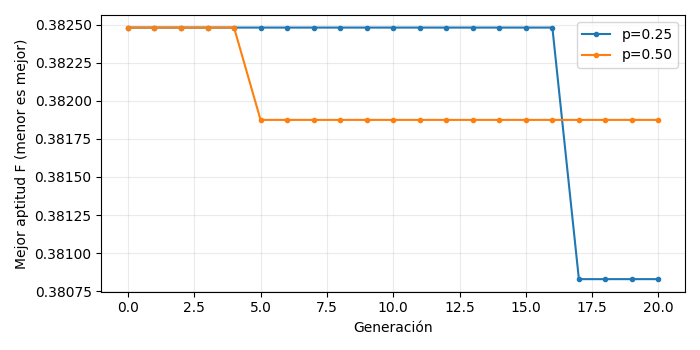

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [ ]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.